<a href="https://colab.research.google.com/github/nurilhuda05/Pembelajaran_Mesin_2026/blob/main/TG6_Regresi_244107020004_Muhammad_Nuril_Huda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **PRAKTIKUM 1**

### **Langkah 1 - Import Library**

In [85]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
import statsmodels.api as sm
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

### **Langkah 2 - Baca Data**

In [86]:
from google.colab import drive
drive.mount('/content/drive')

data = pd.read_csv('/content/drive/MyDrive/Semester 5/Pembelajaran Mesin/Data/dataset.csv')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### **Langkah 3 - Pemahaman Terhadap Data**

In [87]:
# melihat beberapa data awal
data.head()

,Email,Address,Avatar,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
0,mstephenson@fernandez.com,"835 Frank Tunnel\r\nWrightmouth, MI 82180-9605",Violet,34.4973,12.6557,39.5777,4.0826,587.9511
1,hduke@hotmail.com,"4547 Archer Common\r\nDiazchester, CA 06566-8576",DarkGreen,31.9263,11.1095,37.2690,2.6640,392.2049
2,pallen@yahoo.com,"24645 Valerie Unions Suite 582\r\nCobbborough,...",Bisque,33.0009,11.3303,37.1106,4.1045,487.5475
3,riverarebecca@gmail.com,"1414 David Throughway\r\nPort Jason, OH 22070-...",SaddleBrown,34.3056,13.7175,36.7213,3.1202,581.8523
4,mstephens@davidson-herman.com,"14023 Rodriguez Passage\r\nPort Jacobville, PR...",MediumAquaMarine,33.3307,12.7952,37.5367,4.4463,599.4061


In [88]:
# mengecek ukuran data
data.shape

(500, 8)

In [89]:
# informasi tentang data
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Email                 500 non-null    object 
 1   Address               500 non-null    object 
 2   Avatar                500 non-null    object 
 3   Avg. Session Length   500 non-null    float64
 4   Time on App           500 non-null    float64
 5   Time on Website       500 non-null    float64
 6   Length of Membership  500 non-null    float64
 7   Yearly Amount Spent   500 non-null    float64
dtypes: float64(5), object(3)
memory usage: 31.4+ KB


In [90]:
# deskripsi data
data.describe()

,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
count,500.0000,500.0000,500.0000,500.0000,500.0000
mean,33.0532,12.0525,37.0604,3.5335,499.3140
std,0.9926,0.9942,1.0105,0.9993,79.3148
min,29.5324,8.5082,33.9138,0.2699,256.6706
25%,32.3418,11.3882,36.3493,2.9304,445.0383
50%,33.0820,11.9832,37.0694,3.5340,498.8879
75%,33.7120,12.7538,37.7164,4.1265,549.3138
max,36.1397,15.1270,40.0052,6.9227,765.5185


### **Langkah 4 - Visualisasi Data**

/usr/local/lib/python3.13/dist-packages/seaborn/axisgrid.py:2100: UserWarning: The `size` parameter has been renamed to `height`; please update your code.
  warnings.warn(msg, UserWarning)


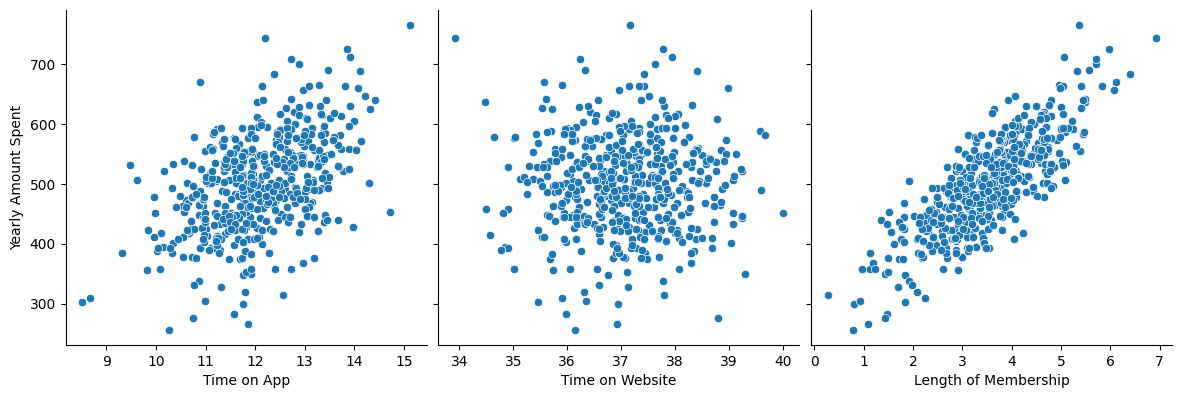

In [91]:
# visualisasi data dengan pairplot
sns.pairplot(data, x_vars=['Time on App', 'Time on Website', 'Length of Membership'],
             y_vars='Yearly Amount Spent', size=4, aspect=1, kind='scatter')
plt.show()

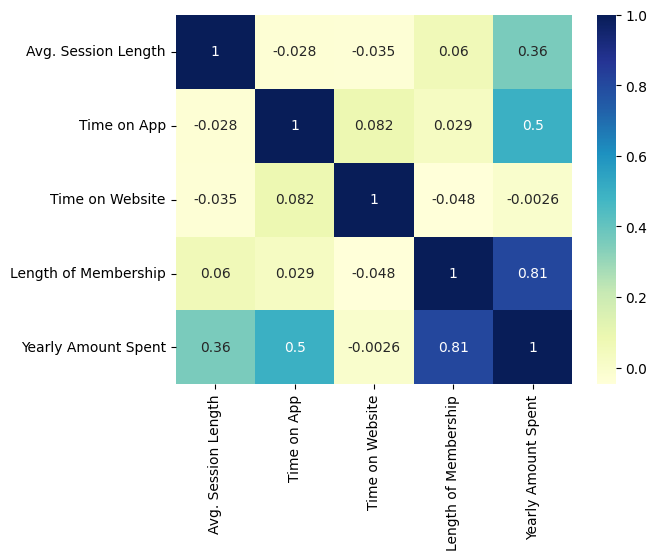

In [92]:
# visualisasi korelasi dengan heatmap
sns.heatmap(data.corr(numeric_only=True), cmap="YlGnBu", annot=True)
plt.show()

### **Langkah 5 - Regresi Linier**

In [93]:
# Membuat variabel bebas X dan Y, contoh pengambilan dari analisis korelasi sebelumnya
X = data['Length of Membership']
y = data['Yearly Amount Spent']

In [94]:
# Pembagian data latih dan data uji dengan proporsi 7:3
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    train_size=0.7,
    test_size=0.3,
    random_state=100
    )

In [95]:
# Training model
X_train_sm = sm.add_constant(X_train)
lr = sm.OLS(y_train, X_train_sm).fit()

In [96]:
# Melihat parameter model (intercept dan slope)
lr.params

,0
const,265.2483
Length of Membership,66.3015


In [97]:
# Menghitung parameter model secara manual
x_mean = X_train.mean()
y_mean = y_train.mean()

# Koefisien regresi (slope)
beta_1 = np.sum((X_train - x_mean) * (y_train - y_mean)) / np.sum((X_train - x_mean) ** 2)

# Intercept
beta_0 = y_mean - beta_1 * x_mean

In [98]:
# Membandingkan parameter hasil manual dengan hasil library (statsmodels)
print("Intercept (manual)  :", beta_0)
print("Intercept (library) :", lr.params['const'])
print()
print("Slope (manual)      :", beta_1)
print("Slope (library)     :", lr.params['Length of Membership'])


Intercept (manual)  : 265.2482985254949
Intercept (library) : 265.2482985254948

Slope (manual)      : 66.30152198546311
Slope (library)     : 66.30152198546311


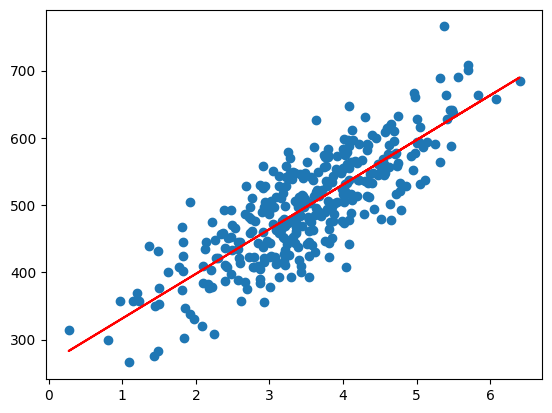

In [99]:
# Visualisasi garis regresi
plt.scatter(X_train, y_train)
plt.plot(X_train, 265.2483 + 66.3015*X_train, 'r')
plt.show()

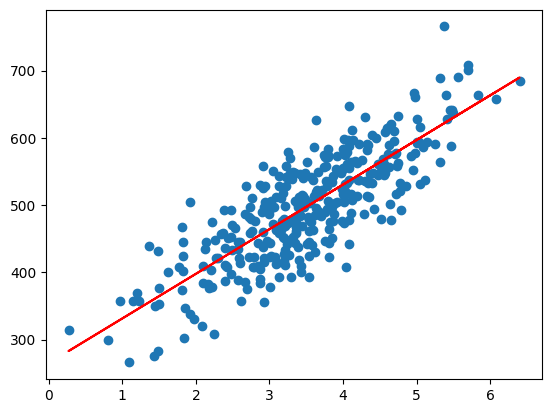

In [100]:
# Visualisasi garis regresi (memakai parameter hasil manual)
plt.scatter(X_train, y_train)
plt.plot(X_train, beta_0 + beta_1*X_train, 'r')
plt.show()

### **Langkah 6 - Analisis Residual**

In [101]:
# Prediksi nilai y_value dari data x yang telah dilatih
y_train_pred = lr.predict(X_train_sm)

# Menghitung residual
res = (y_train - y_train_pred)

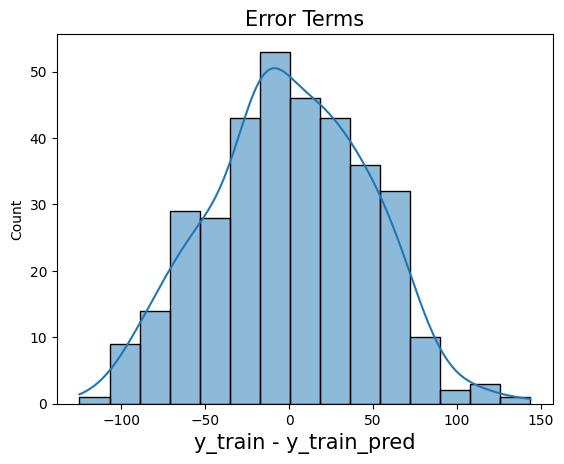

In [102]:
# Histogram residual
fig = plt.figure()
sns.histplot(res, bins=15, kde=True)
plt.title('Error Terms', fontsize=15)
plt.xlabel('y_train - y_train_pred', fontsize=15)
plt.show()

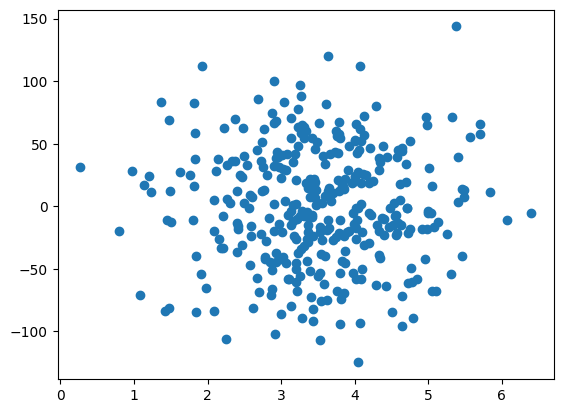

In [103]:
# Scatter plot residual
plt.scatter(X_train, res)
plt.show()

In [104]:
# Prediksi nilai y dari data latih secara manual (memakai parameter hasil manual)
y_train_pred_manual = beta_0 + beta_1 * X_train

# Menghitung residual secara manual
res_manual = y_train - y_train_pred_manual

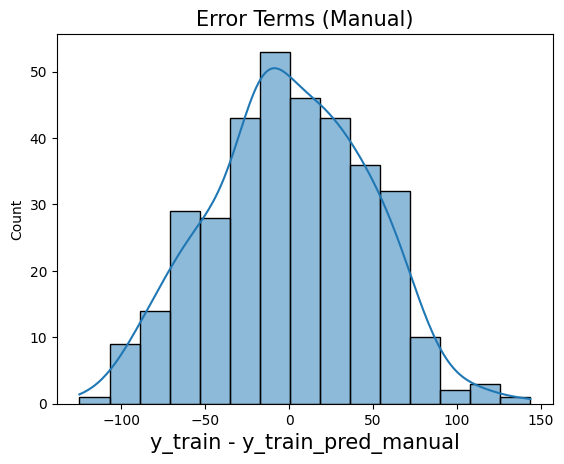

In [105]:
# Histogram residual manual
fig = plt.figure()
sns.histplot(res_manual, bins=15, kde=True)
plt.title('Error Terms (Manual)', fontsize=15)
plt.xlabel('y_train - y_train_pred_manual', fontsize=15)
plt.show()

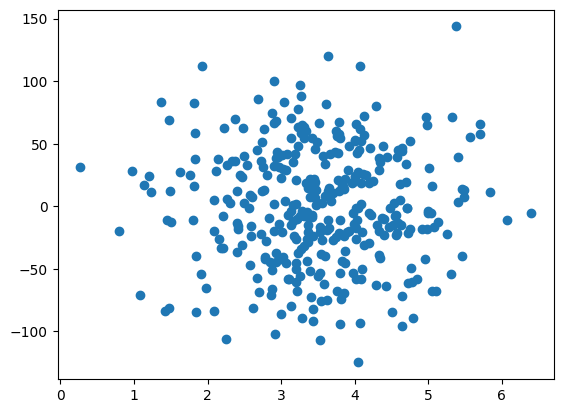

In [106]:
# Scatter plot residual manual
plt.scatter(X_train, res_manual)
plt.show()

In [107]:
# Membandingkan residual hasil manual dan library
print("Rata-rata residual (manual)  :", res_manual.mean())
print("Rata-rata residual (library) :", res.mean())

Rata-rata residual (manual)  : 8.851332365468677e-14
Rata-rata residual (library) : 1.4308300576106247e-13


### **Langkah 7 - Prediksi pada Data Uji dan Evaluasi Model**

In [108]:
# Prediksi pada data uji
X_test_sm = sm.add_constant(X_test)
y_test_pred = lr.predict(X_test_sm)

In [109]:
# Prediksi pada data uji secara manual
y_manual_pred = beta_0 + beta_1 * X_test

In [110]:
# Hitung nilai R-squared, MAE, MSE, dan RMSE
r_squared = r2_score(y_test, y_test_pred)

mae = mean_absolute_error(y_test, y_test_pred)

mse = mean_squared_error(y_test, y_test_pred)

rmse = np.sqrt(mse)

In [111]:
# Hitung nilai R-squared, MAE, MSE, dan RMSE secara manual
RSS = np.sum((y_test - y_manual_pred) ** 2)
TSS = np.sum((y_test - np.mean(y_test)) ** 2)

r2_manual = 1 - (RSS / TSS)
mae_manual = np.mean(np.abs(y_test - y_manual_pred))
mse_manual = np.mean((y_test - y_manual_pred) ** 2)
rmse_manual = np.sqrt(mse_manual)

In [112]:
# Membandingkan hasil manual dan library
hasil = pd.DataFrame({
    'Manual': [r2_manual, mae_manual, mse_manual, rmse_manual],
    'Library': [r_squared, mae, mse, rmse]
}, index=['R-squared', 'MAE', 'MSE', 'RMSE'])

hasil

,Manual,Library
R-squared,0.6119,0.6119
MAE,36.8673,36.8673
MSE,2171.3702,2171.3702
RMSE,46.5980,46.5980


### **Langkah 8 - Visualisasi Hasil**

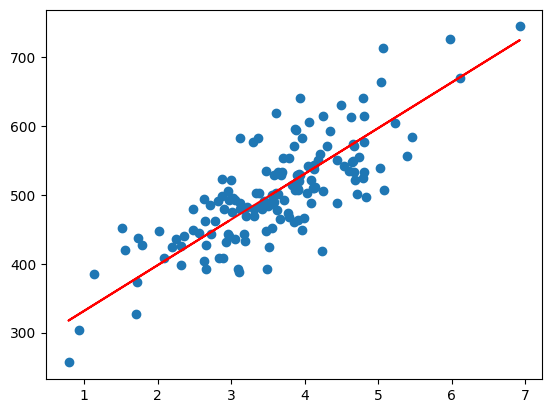

In [113]:
# Visualisasi data uji dan hasil prediksi
plt.scatter(X_test, y_test)
plt.plot(X_test, y_test_pred, 'r')
plt.show()

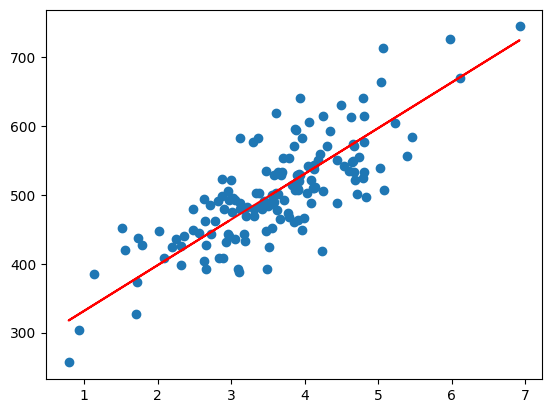

In [114]:
# Visualisasi data uji dan hasil prediksi manual
plt.scatter(X_test, y_test)
plt.plot(X_test, y_manual_pred, 'r')
plt.show()

# **PRAKTIKUM 2**

### **Langkah 1 - Import Library**

In [115]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

### **Langkah 2 - Mengimpor Dataset**

In [116]:
from google.colab import drive
drive.mount('/content/drive')

dataset = pd.read_csv('/content/drive/MyDrive/Semester 5/Pembelajaran Mesin/Data/Posisi_gaji.csv')
X = dataset.iloc[:, 1:2].values
y = dataset.iloc[:, 2].values  # Ubah menjadi satu kolom saja

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### **Langkah 3 - Feature Scaling**

In [117]:
sc_X = StandardScaler()
sc_y = StandardScaler()
X = sc_X.fit_transform(X.reshape(-1, 1))
y = sc_y.fit_transform(y.reshape(-1, 1))

*  StandardScaler mengubah data supaya rata-ratanya 0 dan sebarannya 1.
*  Penskalaan ini diperlukan karena SVR sangat sensitif terhadap skala data. Tingkat posisi (1 sampai 10) dan gaji (puluhan sampai ratusan ribu) selisihnya sangat jauh, sehingga tanpa penskalaan model akan sulit belajar.
*  sc_X untuk fitur (tingkat posisi) dan sc_y untuk target (gaji) dibuat terpisah. Keduanya disimpan karena nanti dipakai lagi untuk menskalakan data baru dan mengembalikan hasil prediksi ke skala asli.
*  reshape(-1, 1) mengubah data menjadi bentuk 2D (satu kolom), karena fit_transform meminta input 2D.

### **Langkah 4 - Fitting SVR ke Dataset**

In [118]:
regressor = SVR(kernel='rbf')
regressor.fit(X, y)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


SVR()

*  SVR(kernel='rbf') membuat model Support Vector Regression dengan kernel RBF (Radial Basis Function). Kernel ini memungkinkan model menangkap hubungan non-linier antara tingkat posisi dan gaji.
*  regressor.fit(X, y) melatih model memakai data yang sudah diskalakan di Langkah 3.

### **Langkah 5 - Visualisasi Hasil SVR**

/tmp/ipykernel_7669/3098558964.py:1: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  X_grid = np.arange(min(X), max(X), 0.01).reshape(-1, 1)


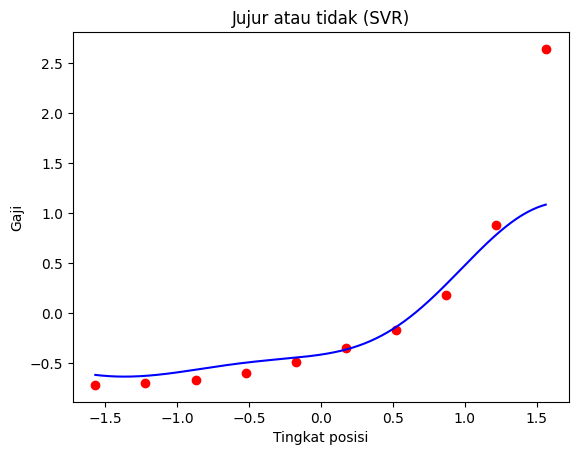

In [119]:
X_grid = np.arange(min(X), max(X), 0.01).reshape(-1, 1)
plt.scatter(X, y, color='red')
plt.plot(X_grid, regressor.predict(X_grid), color='blue')
plt.title('Jujur atau tidak (SVR)')
plt.xlabel('Tingkat posisi')
plt.ylabel('Gaji')
plt.show()

*  X_grid membuat deretan titik dengan jarak 0,01 dari nilai terkecil sampai terbesar X, supaya kurva prediksi tampak halus.
*  Titik merah adalah data asli (sudah diskalakan), dan garis biru adalah hasil prediksi model SVR.

### **Langkah 6 - Prediksi Hasil**

In [120]:

# Buat array 2D yang berisi tingkat posisi yang akan diprediksi
tingkat_posisi_prediksi = np.array([[6.5]])

# Penskalaan fitur untuk data yang akan
tingkat_posisi_prediksi = sc_X.transform(tingkat_posisi_prediksi)

# Melakukan prediksi menggunakan model SVR
gaji_prediksi = regressor.predict(tingkat_posisi_prediksi)

# Kembalikan hasil prediksi ke skala aslinya
gaji_prediksi = sc_y.inverse_transform(gaji_prediksi.reshape(-1, 1))

*  Tingkat posisi 6,5 dibuat dalam bentuk array 2D, karena model meminta input 2D.
*  sc_X.transform menskalakan angka 6,5 dengan skala yang sama seperti data latih. Di sini memakai transform, bukan fit_transform, supaya skalanya tidak dihitung ulang.
*  regressor.predict menghasilkan prediksi gaji, tetapi masih dalam skala standar.
*  sc_y.inverse_transform mengembalikan hasil prediksi ke skala gaji yang asli.

### **Langkah 7 - Menampilkan Hasil**

In [121]:
print("Prediksi Gaji untuk Tingkat Posisi 6.5:", gaji_prediksi[0])

Prediksi Gaji untuk Tingkat Posisi 6.5: [170370.0204065]


*  Kode ini mencetak hasil prediksi gaji untuk tingkat posisi 6,5 yang dihitung di Langkah 6.
*  gaji_prediksi[0] mengambil elemen pertama dari array hasil prediksi.

### **Langkah 8 - Evaluasi Model SVR**

In [122]:
y_actual = y
y_pred = regressor.predict(X)

# Menghitung MAE
mae = mean_absolute_error(y_actual, y_pred)

# Menghitung MSE
mse = mean_squared_error(y_actual, y_pred)

# Menghitung RMSE
rmse = np.sqrt(mse)

# Menghitung R-squared
r2 = r2_score(y_actual, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R-squared:", r2)

MAE: 0.22299274095734414
MSE: 0.24839989293792014
RMSE: 0.4983973243687411
R-squared: 0.7516001070620798


*  y_pred adalah prediksi model untuk semua data latih (X), dibandingkan dengan nilai asli y_actual.

# **TUGAS PRAKTIKUM**

## **Multiple Linear Regression**

### **Langkah 1 - Import Library**

In [123]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

### **Langkah 2 - Baca Data dan Pemahaman Dataset**

In [124]:
# hubungkan Google Drive ke Google Colab
from google.colab import drive
drive.mount('/content/drive')

# baca data
data = pd.read_csv('//content/drive/MyDrive/Semester 5/Pembelajaran Mesin/Data/insurance.csv')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [125]:
# melihat beberapa data awal
data.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.9000,0,yes,southwest,16884.9240
1,18,male,33.7700,1,no,southeast,1725.5523
2,28,male,33.0000,3,no,southeast,4449.4620
3,33,male,22.7050,0,no,northwest,21984.4706
4,32,male,28.8800,0,no,northwest,3866.8552


In [126]:
# mengecek ukuran data
data.shape

(1338, 7)

In [127]:
# informasi tentang data
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [128]:
# mengecek nilai kosong pada setiap kolom
data.isnull().sum()

,0
age,0
sex,0
bmi,0
children,0
smoker,0
region,0
charges,0


### **Langkah 3 - Visualisasi Data**

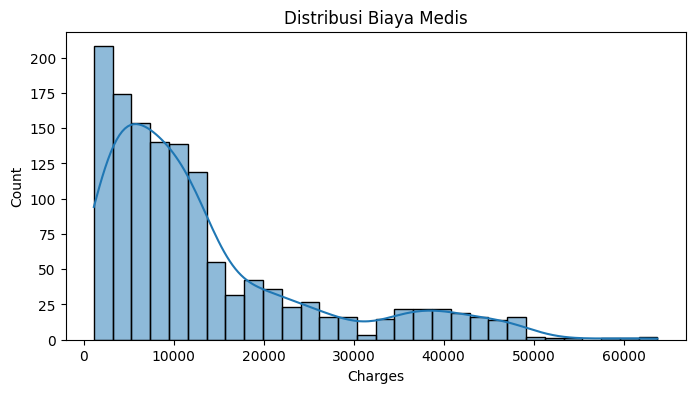

In [129]:
# distribusi biaya medis (variabel target)
plt.figure(figsize=(8, 4))
sns.histplot(data['charges'], bins=30, kde=True)
plt.title('Distribusi Biaya Medis')
plt.xlabel('Charges')
plt.show()

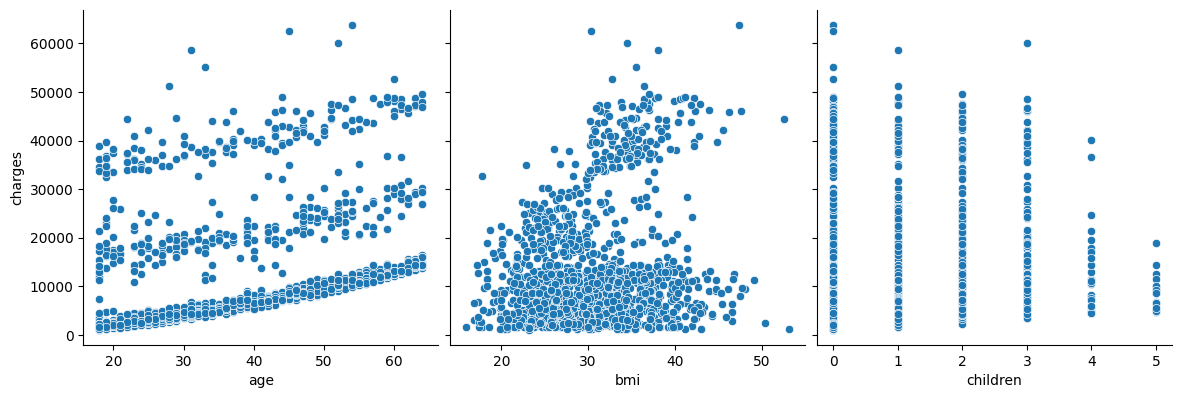

In [130]:
# scatter plot variabel numerik terhadap biaya medis
sns.pairplot(data, x_vars=['age', 'bmi', 'children'],
             y_vars='charges', height=4, aspect=1, kind='scatter')
plt.show()

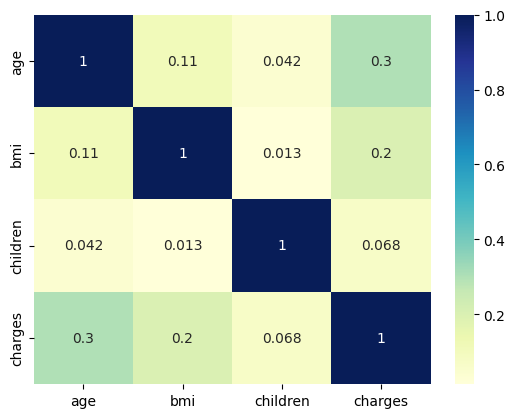

In [131]:
# visualisasi korelasi dengan heatmap (hanya kolom numerik)
sns.heatmap(data.corr(numeric_only=True), cmap="YlGnBu", annot=True)
plt.show()

### **Langkah 4 - Identifikasi Variabel Bebas dan Target**

In [132]:
# mengubah kolom kategorikal menjadi angka (one-hot encoding)
data_encoded = pd.get_dummies(data, columns=['sex', 'smoker', 'region'], drop_first=True, dtype=int)
data_encoded.head()

,age,bmi,children,charges,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27.9000,0,16884.9240,0,1,0,0,1
1,18,33.7700,1,1725.5523,1,0,0,1,0
2,28,33.0000,3,4449.4620,1,0,0,1,0
3,33,22.7050,0,21984.4706,1,0,1,0,0
4,32,28.8800,0,3866.8552,1,0,1,0,0


In [133]:
# memisahkan variabel bebas (X) dan variabel target (y)
X = data_encoded.drop('charges', axis=1)
y = data_encoded['charges']

In [134]:
# melihat fitur yang dipakai dan ukuran datanya
print("Fitur (X):", list(X.columns))
print("Target (y): charges")
print("Ukuran X:", X.shape)
print("Ukuran y:", y.shape)

Fitur (X): ['age', 'bmi', 'children', 'sex_male', 'smoker_yes', 'region_northwest', 'region_southeast', 'region_southwest']
Target (y): charges
Ukuran X: (1338, 8)
Ukuran y: (1338,)


### **Langkah 5 - Pembagian Data Latih dan Data Uji**

In [135]:
# Pembagian data latih dan data uji dengan proporsi 8:2
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
    )

In [136]:
# melihat ukuran data latih dan data uji
print("Ukuran X_train:", X_train.shape)
print("Ukuran X_test :", X_test.shape)
print("Ukuran y_train:", y_train.shape)
print("Ukuran y_test :", y_test.shape)

Ukuran X_train: (1070, 8)
Ukuran X_test : (268, 8)
Ukuran y_train: (1070,)
Ukuran y_test : (268,)


### **Langkah 6 - Feature Scaling**

In [137]:
# Feature Scaling pada kolom numerik
kolom_numerik = ['age', 'bmi', 'children']

scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[kolom_numerik] = scaler.fit_transform(X_train[kolom_numerik])
X_test_scaled[kolom_numerik] = scaler.transform(X_test[kolom_numerik])

In [138]:
# melihat hasil scaling pada data latih
X_train_scaled.head()

,age,bmi,children,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
560,0.4722,-1.7565,0.7343,0,0,1,0,0
1285,0.5433,-1.0331,-0.9112,0,0,0,0,0
1142,0.8987,-0.9437,-0.9112,0,0,0,1,0
969,-0.0254,0.6224,3.2026,0,0,0,1,0
486,1.0409,-1.5049,1.5571,0,0,1,0,0


*  fit_transform dipakai pada data latih, sedangkan data uji hanya memakai transform. Ini mencegah informasi dari data uji “bocor” ke proses pelatihan
*  Pada regresi linier, scaling sebenarnya tidak mengubah hasil prediksi maupun R². Manfaatnya adalah membuat koefisien antar fitur lebih mudah dibandingkan

### **Langkah 7 - Membuat dan Melatih Model**

In [139]:
# Membuat model Multiple Linear Regression
model = LinearRegression()

In [140]:
# Melatih model dengan data latih
model.fit(X_train_scaled, y_train)

LinearRegression()

In [141]:
# Melihat intercept dan koefisien model
print("Intercept:", model.intercept_)
koefisien = pd.DataFrame({'Fitur': X_train_scaled.columns, 'Koefisien': model.coef_})
koefisien

Intercept: 8955.244801502879


,Fitur,Koefisien
0,age,3614.9754
1,bmi,2036.2281
2,children,516.8902
3,sex_male,-18.5917
4,smoker_yes,23651.1289
5,region_northwest,-370.6773
6,region_southeast,-657.8643
7,region_southwest,-809.7994


### **Langkah 8 - Prediksi pada Data Uji**

In [142]:
# Melakukan prediksi pada data uji
y_pred = model.predict(X_test_scaled)

In [143]:
# Membandingkan nilai sebenarnya dengan hasil prediksi
hasil = pd.DataFrame({'Aktual': y_test.values, 'Prediksi': y_pred})
hasil['Selisih'] = hasil['Aktual'] - hasil['Prediksi']
hasil.head(10)

,Aktual,Prediksi,Selisih
0,9095.0683,8969.5503,125.5180
1,5272.1758,7068.7474,-1796.5716
2,29330.9832,36858.4109,-7527.4278
3,9301.8936,9454.6785,-152.7850
4,33750.2918,26973.1735,6777.1183
5,4536.2590,10864.1132,-6327.8542
6,2117.3389,170.2808,1947.0580
7,14210.5359,16903.4503,-2692.9143
8,3732.6251,1092.4309,2640.1942
9,10264.4421,11218.3432,-953.9011


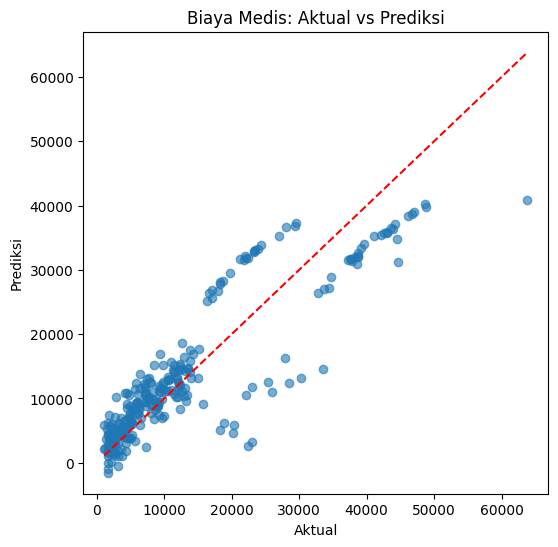

In [144]:
# Visualisasi nilai aktual vs prediksi
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.title('Biaya Medis: Aktual vs Prediksi')
plt.xlabel('Aktual')
plt.ylabel('Prediksi')
plt.show()

### **Langkah 9 - Evaluasi Model**

In [145]:
# Menghitung Rsquared
r2 = r2_score(y_test, y_pred)

# Menghitung MSE
mse = mean_squared_error(y_test, y_pred)

# Menghitung MAE
mae = mean_absolute_error(y_test, y_pred)

# Menghitung RMSE
rmse = np.sqrt(mse)

In [146]:
# Menampilkan hasil evaluasi
print("Rsquared :", r2)
print("MSE      :", mse)
print("MAE      :", mae)
print("RMSE     :", rmse)

Rsquared : 0.7835929767120722
MSE      : 33596915.85136148
MAE      : 4181.194473753652
RMSE     : 5796.284659276275


### **Langkah 10 - Analisis Hasil**

Berdasarkan hasil praktikum, model Multiple Linear Regression untuk memprediksi biaya medis menghasilkan R-squared sebesar 0,7836, artinya model mampu menjelaskan sekitar 78,4% variasi biaya medis, dengan rata-rata kesalahan prediksi (MAE) sekitar 4.181 dolar dan RMSE 5.796 dolar. Dari koefisien model, faktor yang paling berpengaruh terhadap biaya medis adalah status perokok, disusul usia dan BMI, sedangkan jenis kelamin hampir tidak berpengaruh. Meskipun cukup baik, model ini masih punya kelemahan, yaitu sebagian prediksi meleset jauh dan ada yang bernilai negatif, karena hubungan antar variabelnya tidak sepenuhnya linier. Oleh karena itu, hasilnya masih bisa ditingkatkan dengan model non-linier seperti Polynomial Regression, SVR, atau Random Forest.

## **Random Forest**

### **Langkah 1 - Import Library**

In [147]:
from sklearn.ensemble import RandomForestRegressor

### **Langkah 2 - Membuat Model Random Forest**

In [148]:
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)

*  n_estimators=100 berarti hutan terdiri dari 100 pohon keputusan. Semakin banyak pohon, hasilnya biasanya makin stabil, tetapi pelatihan makin lama.
*  random_state=42 mengunci pengacakan supaya hasilnya sama setiap dijalankan.

### **Langkah 3 - Melatih Model Random Forest**

In [149]:
# Melatih model Random Forest dengan data latih (tanpa scaling)
rf_model.fit(X_train, y_train)

RandomForestRegressor(random_state=42)

*  Model dilatih memakai X_train dan y_train yang asli, bukan versi _scaled. Random Forest membagi data dengan aturan “jika-maka”, sehingga skala fitur tidak berpengaruh.

### **Langkah 4 - Prediksi pada Data Uji**

In [150]:
# Melakukan prediksi pada data uji (tanpa scaling)
y_pred_rf = rf_model.predict(X_test)

In [151]:
# Membandingkan nilai sebenarnya dengan hasil prediksi
hasil_rf = pd.DataFrame({'Aktual': y_test.values, 'Prediksi': y_pred_rf})
hasil_rf['Selisih'] = hasil_rf['Aktual'] - hasil_rf['Prediksi']
hasil_rf.head(10)

,Aktual,Prediksi,Selisih
0,9095.0683,9630.2626,-535.1944
1,5272.1758,5570.1967,-298.0209
2,29330.9832,28239.6471,1091.3361
3,9301.8936,12462.6825,-3160.7889
4,33750.2918,34640.8607,-890.5689
5,4536.2590,8225.2969,-3689.0379
6,2117.3389,2099.0457,18.2932
7,14210.5359,14566.8640,-356.3281
8,3732.6251,5626.3898,-1893.7647
9,10264.4421,10791.9984,-527.5563


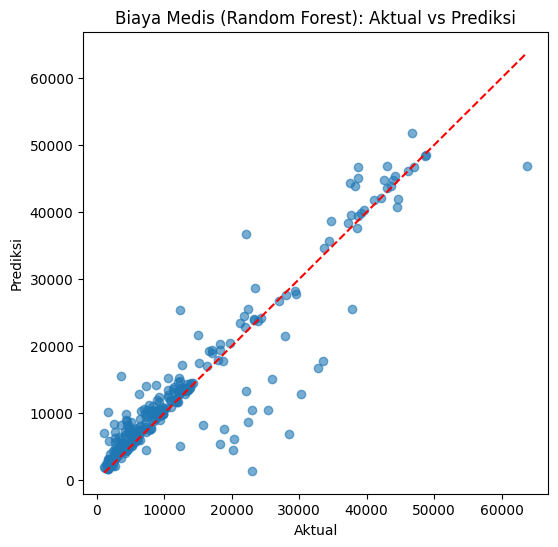

In [152]:
# Visualisasi nilai aktual vs prediksi
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred_rf, alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.title('Biaya Medis (Random Forest): Aktual vs Prediksi')
plt.xlabel('Aktual')
plt.ylabel('Prediksi')
plt.show()

### **Langkah 5 - Evaluasi Model**

In [153]:
# Menghitung R-squared
r2_rf = r2_score(y_test, y_pred_rf)

# Menghitung MSE
mse_rf = mean_squared_error(y_test, y_pred_rf)

# Menghitung MAE
mae_rf = mean_absolute_error(y_test, y_pred_rf)

# Menghitung RMSE
rmse_rf = np.sqrt(mse_rf)

In [154]:
# Menampilkan hasil evaluasi
print("Rsquared :", r2_rf)
print("MSE      :", mse_rf)
print("MAE      :", mae_rf)
print("RMSE     :", rmse_rf)

Rsquared : 0.8651034329144947
MSE      : 20942520.922619622
MAE      : 2550.0784706115096
RMSE     : 4576.299916157115


## **Perbandingan Model**

In [155]:
pd.options.display.float_format = '{:.4f}'.format

# Tabel perbandingan Multiple Linear Regression dan Random Forest
perbandingan = pd.DataFrame({
    'Multiple Linear Regression': [r2, mse, mae, rmse],
    'Random Forest': [r2_rf, mse_rf, mae_rf, rmse_rf]
}, index=['R-squared', 'MSE', 'MAE', 'RMSE'])

perbandingan

,Multiple Linear Regression,Random Forest
R-squared,0.7836,0.8651
MSE,33596915.8514,20942520.9226
MAE,4181.1945,2550.0785
RMSE,5796.2847,4576.2999


In [156]:
# Menentukan model yang lebih baik untuk tiap metrik
lebih_baik = [
    'Random Forest' if r2_rf > r2 else 'Multiple Linear Regression',
    'Random Forest' if mse_rf < mse else 'Multiple Linear Regression',
    'Random Forest' if mae_rf < mae else 'Multiple Linear Regression',
    'Random Forest' if rmse_rf < rmse else 'Multiple Linear Regression'
]


tampil = perbandingan[['Multiple Linear Regression', 'Random Forest']].apply(lambda kolom: kolom.map('{:.4f}'.format))
tampil['Lebih Baik'] = lebih_baik

tampil

,Multiple Linear Regression,Random Forest,Lebih Baik
R-squared,0.7836,0.8651,Random Forest
MSE,33596915.8514,20942520.9226,Random Forest
MAE,4181.1945,2550.0785,Random Forest
RMSE,5796.2847,4576.2999,Random Forest


## **Analisis Kesimpulan**

Berdasarkan hasil praktikum, model Random Forest menunjukkan kinerja yang lebih baik daripada Multiple Linear Regression pada semua metrik evaluasi. Nilai R-squared meningkat dari 0,7836 menjadi 0,8651, yang berarti Random Forest mampu menjelaskan sekitar 86,5% variasi biaya medis, sedangkan Linear Regression hanya sekitar 78,4%. Rata-rata kesalahan prediksi (MAE) juga menurun dari sekitar 4.181 menjadi 2.550, dan RMSE turun dari 5.796 menjadi 4.576, sehingga hasil prediksinya lebih mendekati nilai sebenarnya. Hal ini juga terlihat pada grafik, di mana titik-titik prediksi Random Forest lebih dekat dengan garis merah, serta selisih prediksi pada 10 data pertama yang lebih kecil. Keunggulan ini kemungkinan terjadi karena Random Forest tidak mengasumsikan hubungan yang lurus antar variabel, sehingga dapat menangkap pola yang lebih kompleks, misalnya pengaruh status perokok yang berbeda pada usia dan BMI tertentu. Meskipun demikian, model ini belum sempurna karena masih terdapat beberapa data dengan prediksi yang meleset cukup jauh, terutama pada biaya medis yang sangat tinggi. Dengan demikian, Random Forest lebih sesuai digunakan untuk memprediksi biaya medis pada dataset ini, dan kinerjanya masih dapat ditingkatkan dengan menyesuaikan parameter model.